# Play Analysis — Evaluation

Evaluation notebook for the three rule-based Play_Analysis classifiers —
Formation Classification, Play-Type Classification, and Yard-Line/Hash
Analysis — answering RQ3 (whether presnap detections and field registration
carry enough information to recover a coaching-relevant description of the
play). Plot style/colors match `Player_Detection/evaluation.ipynb` and
`Field_Keypoint_Detection/evaluation/main_evaluation.ipynb` for visual
consistency across the thesis's evaluation notebooks.

Each classifier is evaluated in two phases, the same GT-then-ablation
pattern used throughout this thesis: **GT-input** (ground-truth boxes and
keypoints, isolating whether the classification logic itself is correct)
and **self-detected** (the deployed pipeline's own detections, measuring
real end-to-end capability). Formation Classification additionally has two
mixed configurations that isolate player-detection error from
field-registration error.

## Setup

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

plt.style.use('default')
plt.rcParams.update({
    'figure.facecolor':  'white',
    'axes.facecolor':    'white',
    'savefig.facecolor': 'white',
})

BASE = Path('..')                       # Play_Analysis/ — where *_eval*.json live
OUT  = Path('.') / 'evaluation_output'  # evaluation/evaluation_output/
OUT.mkdir(exist_ok=True)

FORM_ORDER = ['Doubles', 'TRIO', 'WING T', 'TANK', 'TREY']
PLAY_ORDER = ['Pass', 'Run']
HASH_ORDER = ['L', 'M', 'R']

# Same flat-UI palette convention as the other two evaluation notebooks
CONFIG_COLORS = {
    'GT box\nGT kpt':     '#3498db',
    'GT box\ndet. kpt':   '#9b59b6',
    'det. box\nGT kpt':   '#f39c12',
    'det. box\ndet. kpt': '#e74c3c',
}
PHASE_COLORS = {'GT-input': '#3498db', 'Self-detected': '#e74c3c'}


def load(name):
    path = BASE / name
    return json.loads(path.read_text()) if path.exists() else None


def plot_confusion(ax, cm_dict, row_order, title, cmap='Blues'):
    """cm_dict is {true_label: {pred_label: count}} (pd.crosstab().to_dict(orient='index')),
    so pd.DataFrame(cm_dict) alone puts true_label on columns -- transpose first."""
    df = pd.DataFrame(cm_dict).fillna(0).T
    for lbl in row_order:
        if lbl not in df.index:
            df.loc[lbl] = 0
        if lbl not in df.columns:
            df[lbl] = 0
    extra_cols = [c for c in df.columns if c not in row_order]
    col_order = row_order + sorted(extra_cols)
    df = df.loc[row_order, col_order].astype(int)

    im = ax.imshow(df.values, cmap=cmap, aspect='auto')
    ax.set_xticks(range(len(col_order))); ax.set_xticklabels(col_order, rotation=45, ha='right')
    ax.set_yticks(range(len(row_order))); ax.set_yticklabels(row_order)
    ax.set_xlabel('Predicted'); ax.set_ylabel('True')
    ax.set_title(title, fontsize=11)
    vmax = df.values.max() if df.values.size else 1
    for i in range(len(row_order)):
        for j in range(len(col_order)):
            v = df.values[i, j]
            color = 'white' if v > vmax * 0.6 else 'black'
            ax.text(j, i, str(v), ha='center', va='center', color=color, fontsize=9)
    return df


def recall_precision(cm_dict, row_order):
    """Per-label recall/precision from a {true: {pred: count}} confusion dict."""
    df = pd.DataFrame(cm_dict).fillna(0).T
    for lbl in row_order:
        if lbl not in df.index:
            df.loc[lbl] = 0
        if lbl not in df.columns:
            df[lbl] = 0
    df = df.loc[row_order, row_order].astype(int)
    recall = pd.Series({lbl: df.loc[lbl, lbl] / df.loc[lbl].sum() if df.loc[lbl].sum() else float('nan')
                         for lbl in row_order})
    precision = pd.Series({lbl: df.loc[lbl, lbl] / df[lbl].sum() if df[lbl].sum() else float('nan')
                            for lbl in row_order})
    return recall, precision


formation_gt   = load('formation_eval.json')
formation_sd   = load('formation_eval_selfdetected.json')
formation_mix1 = load('formation_eval_mixed_gtbox_detkpt.json')
formation_mix2 = load('formation_eval_mixed_detbox_gtkpt.json')
playtype_gt    = load('play_type_eval.json')
playtype_sd    = load('play_type_eval_selfdetected.json')
yardhash_gt    = load('yard_hash_eval.json')
yardhash_sd    = load('yard_hash_eval_selfdetected.json')
yardhash_mix1  = load('yard_hash_eval_mixed_gtbox_detkpt.json')
yardhash_mix2  = load('yard_hash_eval_mixed_detbox_gtkpt.json')

print('Loaded.')

Loaded.


---
## 1. Formation Classification

**Method.** Rule-based classifier (`classify_formation.py`) mapping presnap
skill-player alignment to one of five formations.

**Why.** Answers whether presnap detections and field registration carry
enough information to recover a coaching-relevant formation label, and
decomposes any accuracy loss into player-detection vs. field-registration
error.

**Data.** 107 tb2026 presnap frames, GT-labeled offensive formation.

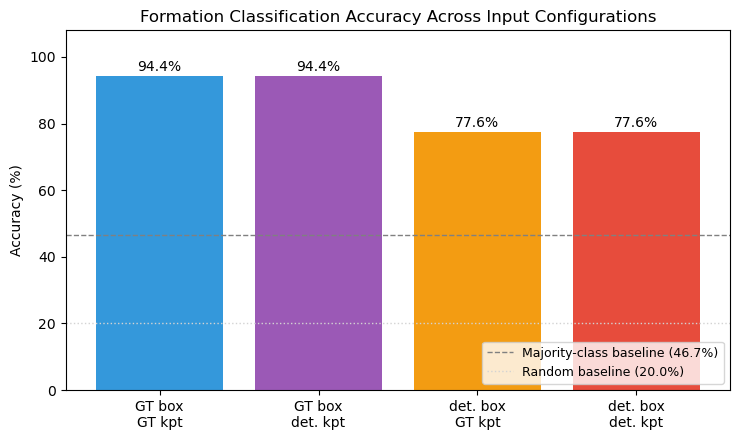

In [2]:
configs = [
    ('GT box\nGT kpt',     formation_gt),
    ('GT box\ndet. kpt',   formation_mix1),
    ('det. box\nGT kpt',   formation_mix2),
    ('det. box\ndet. kpt', formation_sd),
]
labels = [c[0] for c in configs]
accs = [c[1]['accuracy'] * 100 for c in configs]

fig, ax = plt.subplots(figsize=(7.5, 4.5))
bars = ax.bar(labels, accs, color=[CONFIG_COLORS[l] for l in labels])
for b, a in zip(bars, accs):
    ax.text(b.get_x() + b.get_width() / 2, a + 1.5, f'{a:.1f}%', ha='center', fontsize=10)
ax.axhline(46.7, color='gray', linestyle='--', linewidth=1, label='Majority-class baseline (46.7%)')
ax.axhline(20.0, color='lightgray', linestyle=':', linewidth=1, label='Random baseline (20.0%)')
ax.set_ylabel('Accuracy (%)')
ax.set_ylim(0, 108)
ax.set_title('Formation Classification Accuracy Across Input Configurations')
ax.legend(fontsize=9, loc='lower right')
plt.tight_layout()
plt.savefig(OUT / 'formation_accuracy_configs.png', dpi=150, bbox_inches='tight')
plt.show()

**Confusion matrices.** GT-input isolates the classification logic; self-detected
shows the deployed pipeline's real confusions (mostly collapsing toward TANK and,
before the tolerant-match fix, toward "unknown" — see `TODO.md`).

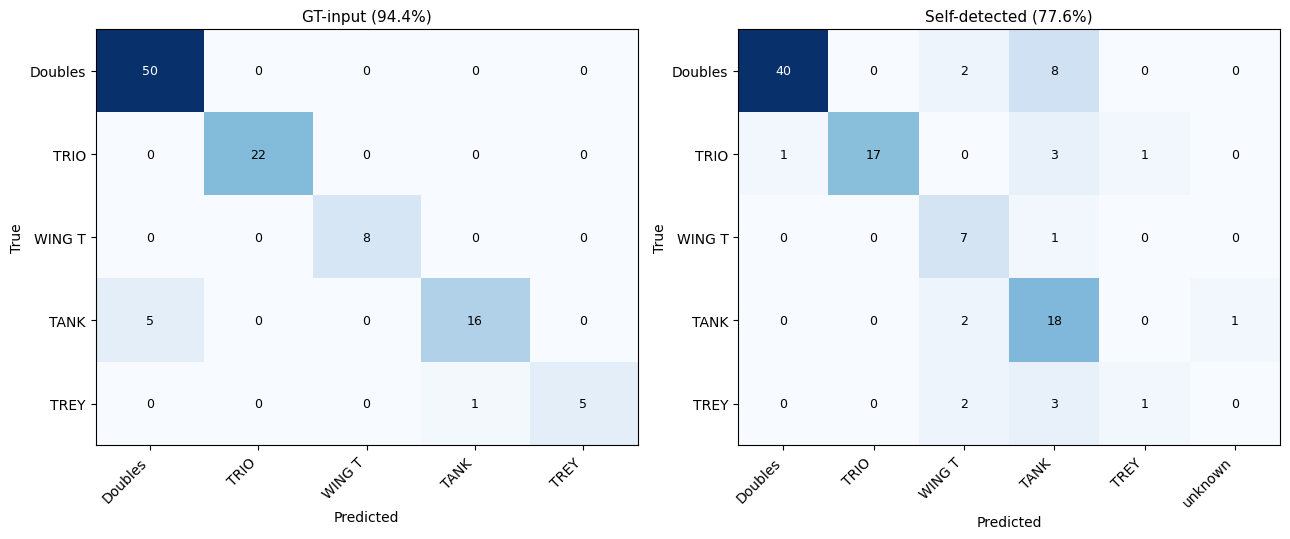

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))
plot_confusion(axes[0], formation_gt['confusion_matrix'], FORM_ORDER,
               f"GT-input ({formation_gt['accuracy']:.1%})")
plot_confusion(axes[1], formation_sd['confusion_matrix'], FORM_ORDER,
               f"Self-detected ({formation_sd['accuracy']:.1%})")
plt.tight_layout()
plt.savefig(OUT / 'formation_confusion_matrices.png', dpi=150, bbox_inches='tight')
plt.show()

In [4]:
recall_df = pd.DataFrame({
    'GT-input':       pd.Series(formation_gt['recall_per_formation']),
    'Self-detected':  pd.Series(formation_sd['recall_per_formation']),
}).reindex(FORM_ORDER)
display(recall_df.style.format('{:.1%}'))

,GT-input,Self-detected
Doubles,100.0%,80.0%
TRIO,100.0%,77.3%
WING T,100.0%,87.5%
TANK,76.2%,85.7%
TREY,83.3%,16.7%


---
## 2. Play-Type Classification

**Method.** Rule-based classifier (`play_type_classification.py`) comparing
QB and offensive-line downfield movement slopes over the tracked clip.

**Why.** Answers whether tracked post-snap movement carries a usable
run/pass signal, and how much that signal degrades once tracking is
initialized from real (not ground-truth) detections.

**Data.** 107 tb2026 clips, GT-labeled play type.

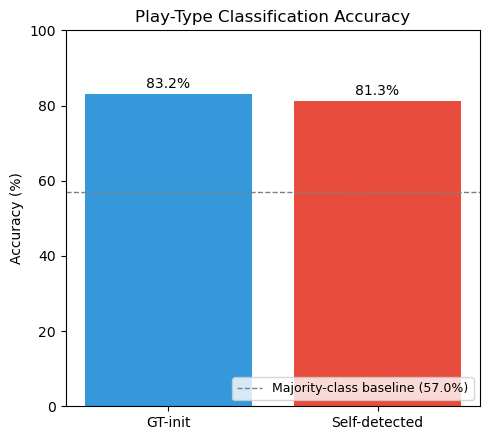

In [5]:
fig, ax = plt.subplots(figsize=(5, 4.5))
phases = ['GT-init', 'Self-detected']
accs = [playtype_gt['accuracy'] * 100, playtype_sd['accuracy'] * 100]
bars = ax.bar(phases, accs, color=[PHASE_COLORS['GT-input'], PHASE_COLORS['Self-detected']])
for b, a in zip(bars, accs):
    ax.text(b.get_x() + b.get_width() / 2, a + 1.5, f'{a:.1f}%', ha='center', fontsize=10)
ax.axhline(57.0, color='gray', linestyle='--', linewidth=1, label='Majority-class baseline (57.0%)')
ax.set_ylabel('Accuracy (%)')
ax.set_ylim(0, 100)
ax.set_title('Play-Type Classification Accuracy')
ax.legend(fontsize=9, loc='lower right')
plt.tight_layout()
plt.savefig(OUT / 'playtype_accuracy.png', dpi=150, bbox_inches='tight')
plt.show()

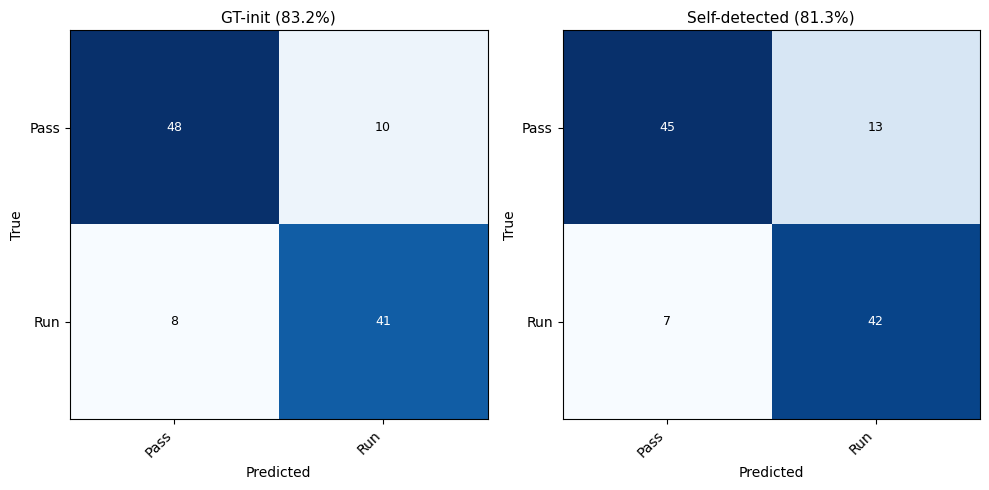

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(10, 5))
plot_confusion(axes[0], playtype_gt['confusion_matrix'], PLAY_ORDER,
               f"GT-init ({playtype_gt['accuracy']:.1%})")
plot_confusion(axes[1], playtype_sd['confusion_matrix'], PLAY_ORDER,
               f"Self-detected ({playtype_sd['accuracy']:.1%})")
plt.tight_layout()
plt.savefig(OUT / 'playtype_confusion_matrices.png', dpi=150, bbox_inches='tight')
plt.show()

---
## 3. Yard-Line and Hash Analysis

**Method.** Rule-based field-position readout (`yard_hash_analysis.py`)
from the offensive line's downfield and lateral position at the snap.

**Why.** Answers whether field registration alone (no tracking needed) is
accurate enough to recover field position, the most geometry-dependent of
the three tasks.

**Data.** 107 tb2026 presnap frames, GT-labeled yard line and hash.

In [7]:
yardhash_configs = [
    ('GT box\nGT kpt',     yardhash_gt),
    ('GT box\ndet. kpt',   yardhash_mix1),
    ('det. box\nGT kpt',   yardhash_mix2),
    ('det. box\ndet. kpt', yardhash_sd),
]
yardline_df = pd.DataFrame(
    {label.replace('\n', ' / '): cfg['yardline'] for label, cfg in yardhash_configs}
).T
yardline_df.columns = ['Mean err. (yd)', 'Median err. (yd)', 'Max err. (yd)']
display(yardline_df.style.format('{:.2f}'))

,Mean err. (yd),Median err. (yd),Max err. (yd)
GT box / GT kpt,0.54,0.38,2.09
GT box / det. kpt,0.77,0.47,3.12
det. box / GT kpt,0.59,0.43,2.17
det. box / det. kpt,0.79,0.53,2.86


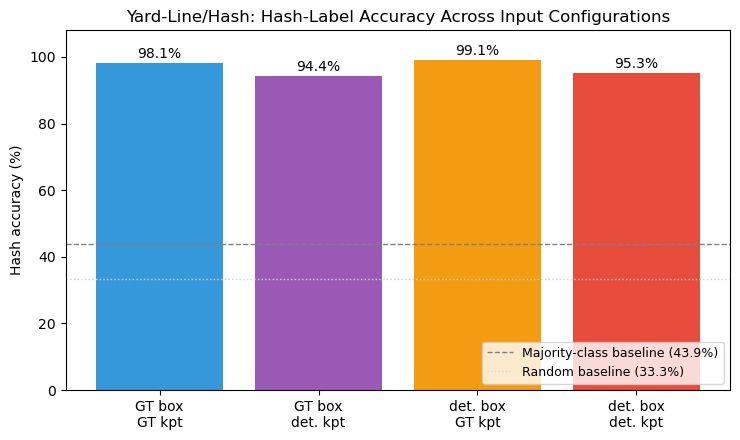

In [8]:
labels = [c[0] for c in yardhash_configs]
hash_accs = [c[1]['hash']['accuracy'] * 100 for c in yardhash_configs]

fig, ax = plt.subplots(figsize=(7.5, 4.5))
bars = ax.bar(labels, hash_accs, color=[CONFIG_COLORS[l] for l in labels])
for b, a in zip(bars, hash_accs):
    ax.text(b.get_x() + b.get_width() / 2, a + 1.5, f'{a:.1f}%', ha='center', fontsize=10)
ax.axhline(43.9, color='gray', linestyle='--', linewidth=1, label='Majority-class baseline (43.9%)')
ax.axhline(33.3, color='lightgray', linestyle=':', linewidth=1, label='Random baseline (33.3%)')
ax.set_ylabel('Hash accuracy (%)')
ax.set_ylim(0, 108)
ax.set_title('Yard-Line/Hash: Hash-Label Accuracy Across Input Configurations')
ax.legend(fontsize=9, loc='lower right')
plt.tight_layout()
plt.savefig(OUT / 'yardhash_accuracy.png', dpi=150, bbox_inches='tight')
plt.show()

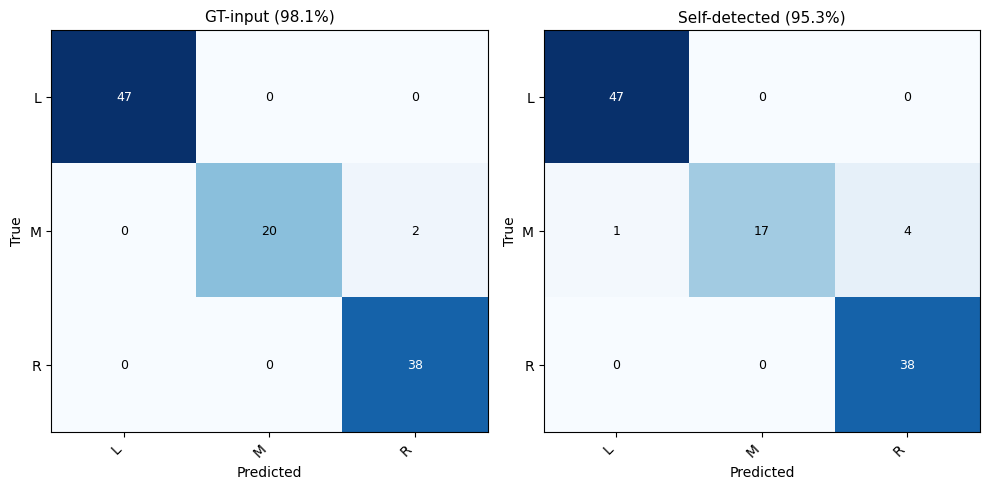

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(10, 5))
plot_confusion(axes[0], yardhash_gt['hash']['confusion_matrix'], HASH_ORDER,
               f"GT-input ({yardhash_gt['hash']['accuracy']:.1%})")
plot_confusion(axes[1], yardhash_sd['hash']['confusion_matrix'], HASH_ORDER,
               f"Self-detected ({yardhash_sd['hash']['accuracy']:.1%})")
plt.tight_layout()
plt.savefig(OUT / 'yardhash_confusion_matrices.png', dpi=150, bbox_inches='tight')
plt.show()

In [10]:
gt_recall, gt_precision = recall_precision(yardhash_gt['hash']['confusion_matrix'], HASH_ORDER)
sd_recall, sd_precision = recall_precision(yardhash_sd['hash']['confusion_matrix'], HASH_ORDER)
hash_rp_df = pd.DataFrame({
    'GT recall':      gt_recall,
    'GT precision':   gt_precision,
    'Self-det. recall':    sd_recall,
    'Self-det. precision': sd_precision,
}).reindex(HASH_ORDER)
display(hash_rp_df.style.format('{:.1%}'))

,GT recall,GT precision,Self-det. recall,Self-det. precision
L,100.0%,100.0%,100.0%,97.9%
M,90.9%,100.0%,77.3%,100.0%
R,100.0%,95.0%,100.0%,90.5%
